# 동결 Chronos2 + MORA: 실제 수요 L52/H27 비교

## 핵심 결과
- 시험 부품 1,050개, 시작 주차 202518, 예측 정답 28,350개에 대한 짝지은 비교
- MAE: **2.215364 → 2.216366** (0.05% 증가)
- RMSE: **5.606588 → 5.604311**
- 부품별 MAE 개선 517개 / 동일 0개 / 악화 533개
- 공식 Chronos2 가중치와 기존 모델 코드 변경 없음. MORA 보정 파라미터만 적합

한 시작 주차에서 MORA 적합에 쓰지 않은 부품의 시험 결과이며 모든 법인·시점에 대한 성능 보장은 아님.
이 노트북은 **저장된 결과 확인·재계산용**으로, 기본 실행 시 학습·추론·DB 작업을 다시 수행하지 않음.


## 1. 환경과 결과 위치

저장소 루트를 자동으로 찾은 뒤 결과 파일을 읽는 구성. NumPy·pandas·Matplotlib·SciPy·IPython 필요.
공식 가중치를 다시 호출하지 않으므로 이 노트북의 결과 재생에는 `chronos` 패키지 불필요.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates if (path / "src/modeling_module").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RUN = ROOT / 'artifacts/mora/chronos2_frozen_l52_h27_20261120_seed42'
summary = json.loads((RUN / "summary.json").read_text())
experiment = json.loads((RUN / "experiment.json").read_text())
audit = json.loads((RUN / "independent_audit.json").read_text())
assert summary["status"] == "complete" and audit["status"] == "passed"
display(Markdown(f"결과 위치: `{RUN}`"))
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})


결과 위치: `/Users/igwanhyeong/PycharmProjects/ts_forecaster_lib/artifacts/mora/chronos2_frozen_l52_h27_20261120_seed42`

## 2. 기존 데이터 분할 유지

부품 ID와 정답 기간을 모두 분리한 기존 계약 유지. 입력 52주는 정답 시작 직전 관측값만 사용.

| 구분 | 부품 | 정답 허용 기간 | 선택 창 |
|---|---:|---|---:|
| 보정 적합 | 4,900 | 201801–202442 | 부품당 4개, 총 19,600개 |
| 보정 강도 결정 | 1,050 | 202443–202517 | 시작 202443, 총 1,050개 |
| 최종 시험 | 1,050 | 202518–202544 | 시작 202518, 총 1,050개 |

실제 관측된 0수요는 그대로 유지. 결측의 0 대체나 부품 번호 앞순서 선택 없음.
학습 가능 창 1,080,909개 중 수요량과 무관한 ID·주차 해시로 19,600개 선택.
검증·시험 부품은 전부 포함하며 조건 미달 제외 부품은 0개.


In [2]:
eligibility = pd.DataFrame(summary["eligibility"]).T
display(eligibility[["assigned_parts", "eligible_parts", "eligible_windows", "selected_windows", "target_start", "target_end"]])
display(pd.DataFrame([{"source_sha256": summary["source_sha256"],
                       "split_manifest_sha256": summary["split_manifest_sha256"],
                       "zero_semantics": summary["zero_semantics"]}]).T)


,assigned_parts,eligible_parts,eligible_windows,selected_windows,target_start,target_end
train,4900,4900,1080909,19600,201801,202442
validation,1050,1050,1050,1050,202443,202517
test,1050,1050,1050,1050,202518,202544


,0
source_sha256,328f547d5eb0a50c80dc60dc7bb89c09799599f8f6b867...
split_manifest_sha256,a7b16441549e128297797be87d1c0853690a89bc1dc50b...
zero_semantics,observed_zero


## 3. Chronos2와 MORA의 역할 분리

`과거 52주 → 동결 공식 Chronos2 → 원본 P50 → 독립 MORA → 보정 점예측 27주`

Chronos2는 공식 사전학습 가중치의 CPU FP32 추론이며 학습 가능한 파라미터 0개.
MORA는 논문 수식의 독립 구현으로, 저자 원본 코드를 복사한 구현이 아님.

기존 분할에서 부품 ID가 겹치지 않으므로 `pooled_series`로 학습 부품의 공통 보정 규칙을 새 부품에 적용.
수천 부품을 동시 채널로 넣는 것이 아니라 각 창의 채널은 `demand_qty` 1개.
이는 논문의 단일 시계열 설정과 구분되는 연구 확장.

학습 내부는 겹치는 관측·정답 구간을 제거한 4개 outer/inner 블록 검증.
검증 구간에는 H27 시작점이 하나뿐이므로 보정 강도 계산의 4개 그룹은 시간 그룹이 아닌 부품 그룹.
시험 정답은 보정기 저장 이후 평가에만 사용. 시험 결과를 보고 재적합하지 않은 비교.


In [3]:
display(pd.DataFrame(list(experiment["mora"].items()), columns=["설정", "값"]))
frozen = summary["frozen_checks"]
display(pd.DataFrame(list(frozen.items()), columns=["불변 검사", "결과"]))
assert frozen["parameters_identical"] and frozen["model_sources_identical"]
assert frozen["trainable_parameters"] == 0


,설정,값
0,lookback,52
1,horizon,27
2,period,52
3,coarse_max,64
4,min_bin_size,4
5,correction_rank,16
6,taper_steps,4
7,ridge_strength,10.0
8,shrinkage,0.5
9,structured_mix,0.25


,불변 검사,결과
0,parameter_fingerprint_before,40174b2b0282a1c048f7cf2c0094f9178daff6deb09787...
1,parameter_fingerprint_after,40174b2b0282a1c048f7cf2c0094f9178daff6deb09787...
2,parameters_identical,True
3,trainable_parameters,0
4,model_sources_identical,True
5,source_identical,True
6,weights_file_identical,True
7,config_file_identical,True
8,split_manifest_identical,True
9,adapter_identical_during_test,True


## 4. 같은 원본 예측을 두 경로에 사용했는지 확인

기준선 P50을 캐시에 한 번 저장한 뒤 동일한 값을 MORA 입력으로 재사용.
원본 P10/P50/P90은 그대로 보존하며 MORA 출력은 **보정된 점예측**일 뿐 보정 분위수는 아님.
반올림과 음수 절단은 양쪽 모두 적용하지 않은 조건.


In [4]:
arrays = np.load(RUN / "test_comparison.npz", allow_pickle=False)
original = np.load(RUN / "test_arrays.npz", allow_pickle=False)
actual = arrays["target"]
baseline = arrays["baseline"]
corrected = arrays["corrected"]
np.testing.assert_array_equal(baseline[:, :, 0], original["original_quantiles"][:, :, 1])
np.testing.assert_array_equal(actual, original["target"])
np.testing.assert_array_equal(baseline[:, 0], corrected[:, 0])
display(pd.DataFrame({"배열": ["과거", "정답", "기준선", "보정 점예측", "원본 분위수"],
                       "shape": [original["history"].shape, actual.shape, baseline.shape,
                                 corrected.shape, original["original_quantiles"].shape]}))


,배열,shape
0,과거,"(1050, 52, 1)"
1,정답,"(1050, 27, 1)"
2,기준선,"(1050, 27, 1)"
3,보정 점예측,"(1050, 27, 1)"
4,원본 분위수,"(1050, 27, 3)"


## 5. 실제 성능 재계산

MAE = 평균 절대 오차, RMSE = 제곱 오차 평균의 제곱근.
WAPE = 전체 절대 오차 합 / 실제 수요 합. 실제 수요 합 0인 부품의 개별 WAPE는 정의하지 않으며 별도 집계.
같은 부품의 27개 주차를 독립 표본으로 간주하지 않고 부품 단위 재표집으로 신뢰구간 계산.
아래 기본 셀은 보정기를 재학습하지 않는 저장 결과 재계산.


In [5]:
from model_test.mora.comparison_metrics import paired_comparison
recalculated = paired_comparison(actual, baseline, corrected)
for name in ("baseline", "mora"):
    for metric in ("mae", "rmse", "wape"):
        np.testing.assert_allclose(recalculated[name][metric], summary["comparison"][name][metric], rtol=1e-12)
table = pd.DataFrame({"Chronos2 P50": recalculated["baseline"], "Chronos2 + MORA": recalculated["mora"]})
display(table.loc[["mae", "rmse", "wape", "macro_part_rmse", "zero_total_parts", "zero_total_parts_mae", "negative_predictions"]])
display(pd.DataFrame([recalculated["part_mae"]]))
display(pd.DataFrame([recalculated["paired_part_bootstrap"]]))


,Chronos2 P50,Chronos2 + MORA
mae,2.215364,2.216366
rmse,5.606588,5.604311
wape,0.115083,0.115135
macro_part_rmse,2.686577,2.687452
zero_total_parts,657.000000,657.000000
zero_total_parts_mae,2.394199,2.395882
negative_predictions,6393.000000,6892.000000


,improved,unchanged,worsened,tolerance
0,517,0,533,1.000000e-10


,draws,seed,statistic,mean_delta,percentile_95_ci
0,2000,42,mora_minus_baseline_mae,0.001002,"[0.000253023419836878, 0.0016971855126546817]"


## 6. 예측 거리별 오차와 부품별 편차

첫 예측 주차는 MORA 기저 구조상 보정하지 않는 값. 2–27주 오차를 확인할 때 전체 평균 개선과 부품별 악화를 함께 확인할 필요.


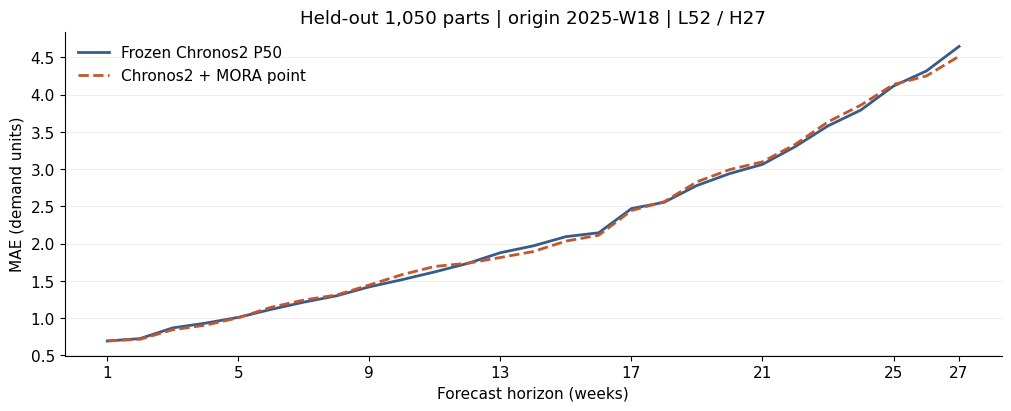

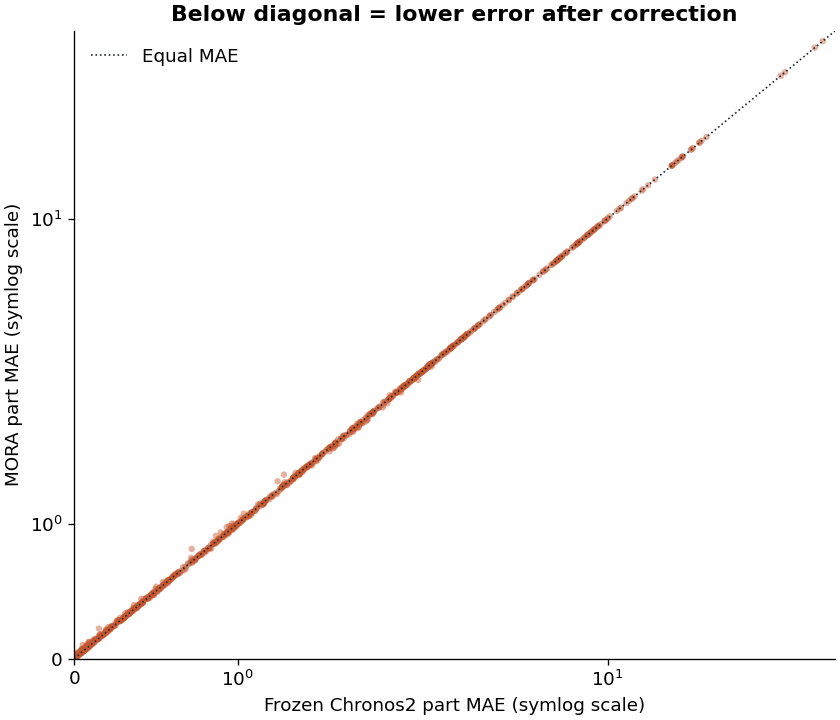

In [6]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for values, color, label, style in [(baseline, "#355C8A", "Frozen Chronos2 P50", "-"),
                                     (corrected, "#C4562D", "Chronos2 + MORA point", "--")]:
    ax.plot(np.arange(1, 28), np.abs(values - actual).mean(axis=(0, 2)), style,
            color=color, label=label, linewidth=2)
ax.set(xlabel="Forecast horizon (weeks)", ylabel="MAE (demand units)",
       title="Held-out 1,050 parts | origin 2025-W18 | L52 / H27", xticks=[1, 5, 9, 13, 17, 21, 25, 27])
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
plt.show()
display(Image(filename=str(RUN / "part_mae.png"), width=700))


## 7. 결과가 좋은 부품만 고르지 않은 예시

시험 ID의 SHA-256 순서로 4개 선택. 성능 순위나 수요 패턴으로 선택한 대표 표본이 아님.
달력 날짜 축 사용으로 연말·연초의 YYYYWW 숫자 간격 왜곡 방지.


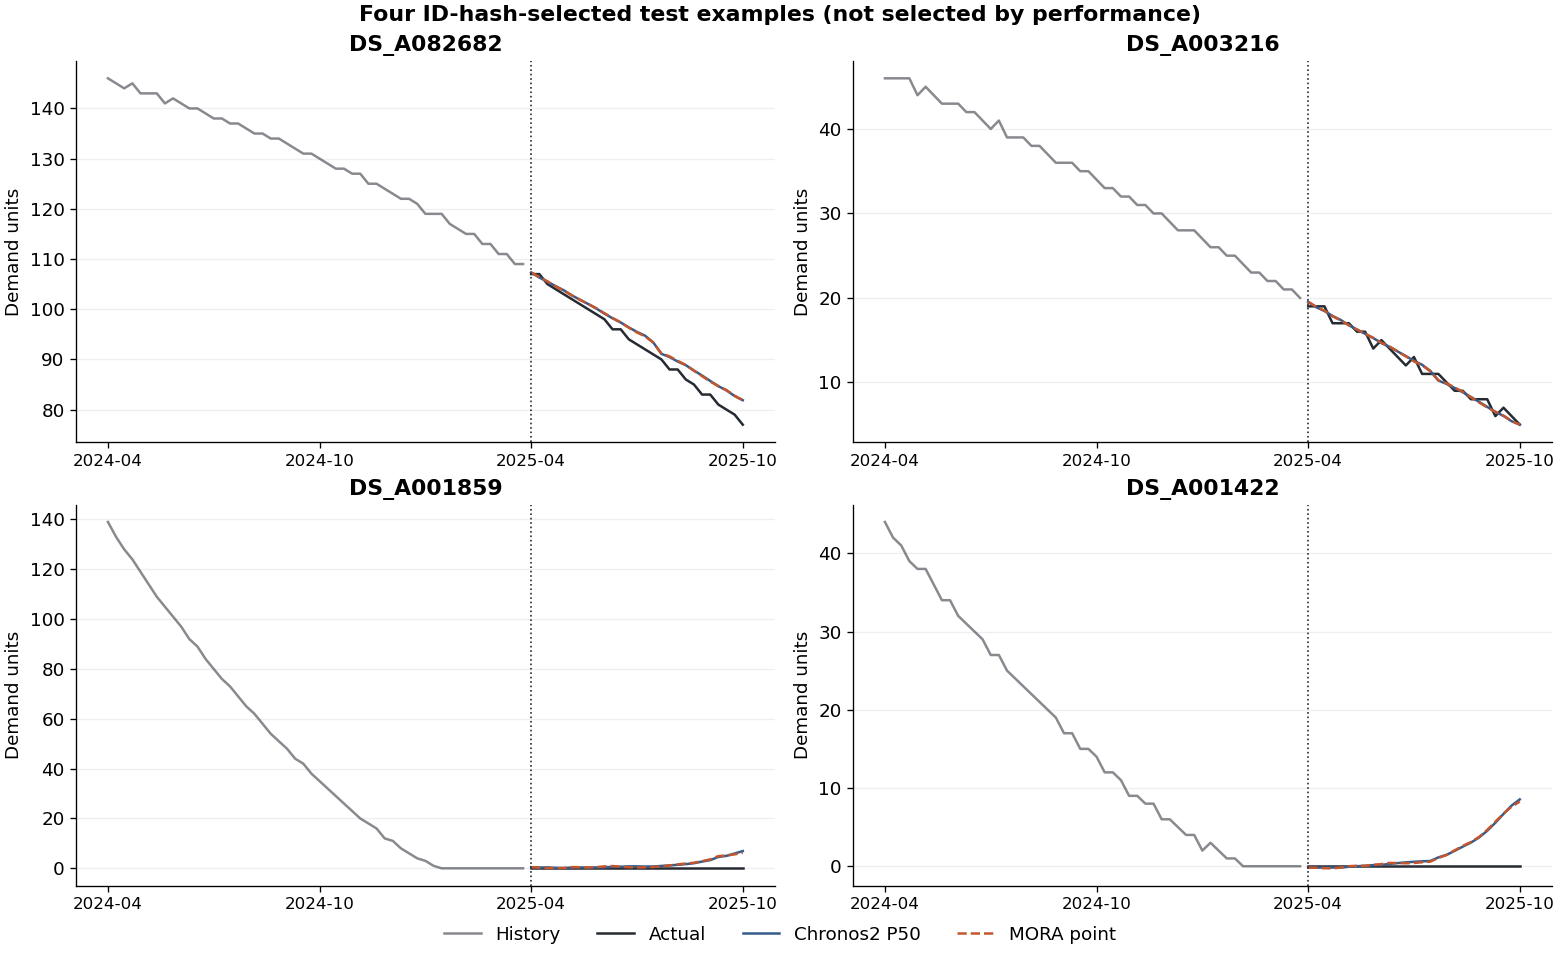

In [7]:
display(Image(filename=str(RUN / "forecast_examples.png"), width=1100))


## 8. 저장된 보정기만으로 동일 결과 재생

시험 정답은 `ForecastQuery`에 전달하지 않는 구조. 원본 과거와 P50만 전달하여 보정 결과 재현.
체크포인트 로드는 적합이나 검증 강도 재계산이 아님.


In [8]:
from modeling_module.forecast_adapters.contracts import ForecastQuery
from modeling_module.forecast_adapters.MORA import MORAAdapter
adapter = MORAAdapter.load(RUN / "adapter.npz")
query = ForecastQuery(original["history"], baseline, original["origins"], ("demand_qty",),
                      tuple(original["series_ids"].tolist()), experiment["baseline"])
replay = adapter.predict(query)
np.testing.assert_array_equal(replay.point, corrected)
display(Markdown("동일 환경에서 저장·복원 전후 보정 점예측의 완전 일치 확인."))
display(pd.DataFrame(adapter.diagnostics["calibration_details"]))


동일 환경에서 저장·복원 전후 보정 점예측의 완전 일치 확인.

,calibrated_objective,channel,group_scales,uncorrected_objective
0,0.999498,0,"[0.0005423695139798076, 0.5465654985918887, 1....",1.000018


## 해석 범위와 다음 작업

- 한 시험 시작 주차에 대한 결과. 여러 시작 주차나 고객 환경으로의 일반화 미검증
- 검증 강도는 한 주차의 별도 부품들로 결정. 논문의 시간 블록 검증 재현으로 설명하지 않을 조건
- 전체 오차 감소가 모든 부품의 개선을 의미하지 않는 점에 유의
- 음수 절단·계절 주기·rank 변경은 새 실험 조건. 이번 시험을 보고 바꾸면 같은 시험을 최종 미사용 시험으로 재사용 불가
- 원본 분위수는 보정하지 않았으므로 보정 후 예측구간 신뢰도 개선 주장 불가
- 원천은 사용자가 제공한 로컬 스냅샷이며 실시간 운영 DB의 출처·최신성 별도 확인 필요
- 공식 Chronos2 사전학습 데이터와의 중복 여부는 확인되지 않은 상태. 부품 분리는 이번 MORA 적합 데이터 내부의 계약

원천·분할·가중치·실험 설정 해시, 전체 예측 CSV, 보정기와 독립 검산 JSON은 결과 디렉토리에 보관.
